# BT4012 Competition 2026 – Illicit Bitcoin Transaction Detection

**Goal:** predict the probability that each test transaction is illicit. Metric: ROC-AUC.

**Pipeline**
1. Load data, clean labels (1 = illicit, 0 = licit, everything else = unlabelled).
2. Graph feature engineering on the full transaction graph (train + unlabelled + test): degrees, 2-hop reach, component size, and direction-aware neighbour means (*where the money came from* vs *where it went*).
3. Per-time-step percentile ranks of the local features, to make features robust to drift between periods.
4. **Time-based validation**: always train on earlier time steps and validate on later ones, because the test set is in the future.
5. Compare feature sets with LightGBM, check for train-vs-test drift (adversarial validation), then compare LightGBM / Random Forest / Extra Trees and rank-averaged ensembles.
6. Refit on all labelled data and write two submissions: best single model and best ensemble.

**How to run:** put `train.csv`, `test.csv`, `txs_edgelist.csv`, `sample_submission.csv` in a `data/` folder next to this notebook (or attach the competition data on Kaggle) and *Run All*. Outputs: `submission_lgb.csv`, `submission_ensemble.csv`, `cv_results.csv`.

In [1]:
# ===== 1. Setup =====
import os, glob, random, time, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
import lightgbm as lgb
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

def find_data_dir():
    # Look for the competition files locally first, then in Kaggle's input folder
    candidates = ['./data', '.'] + glob.glob('/kaggle/input/*') + glob.glob('/kaggle/input/*/*')
    for d in candidates:
        if os.path.exists(os.path.join(d, 'train.csv')):
            return d
    raise FileNotFoundError('Put train.csv, test.csv, txs_edgelist.csv and sample_submission.csv in ./data')

DATA_DIR = find_data_dir()
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'
print('Data dir:', DATA_DIR, '| Output dir:', OUT_DIR)

Data dir: ./data | Output dir: .


## 2. Load data
Features are anonymised. Feature columns are detected automatically: every numeric column except `txId`, `time_step` and `label`. Following the Elliptic dataset layout, the first 93 are treated as **local** (the transaction itself) and the rest as **aggregated** (statistics over 1-hop neighbours). `time_step` is deliberately **not** used as a model feature: every test time step is unseen, so a model cannot learn anything transferable from it.

In [2]:
# ===== 2. Load data =====
t0 = time.time()
train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
edges = pd.read_csv(os.path.join(DATA_DIR, 'txs_edgelist.csv'))
sample = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))
print(f'train {train.shape} | test {test.shape} | edges {edges.shape} | sample {sample.shape} | {time.time() - t0:.0f}s')

# Feature columns = every numeric column present in both train and test, except id / time / label columns.
# Detected from the file itself, so it works whatever the columns are called.
NON_FEAT = {'txid', 'time_step', 'timestep', 'time step', 'label', 'class', 'y', 'index', 'is_test'}
FEAT = [c for c in train.columns
        if c.strip().lower() not in NON_FEAT and c in test.columns
        and pd.api.types.is_numeric_dtype(train[c])]
# Local features: columns with 'local' in the name if there are any, otherwise the first 93 (Elliptic layout)
local_named = [c for c in FEAT if 'local' in c.lower()]
LOCAL = local_named if local_named else FEAT[:93]
AGG = [c for c in FEAT if c not in LOCAL]
print(len(FEAT), 'features:', len(LOCAL), 'local +', len(AGG), 'other')
print('First feature columns:', FEAT[:5], '| last:', FEAT[-3:])
assert len(FEAT) > 0 and len(LOCAL) > 0, 'No feature columns found - check train.columns'

# float32 halves memory use
for df in (train, test):
    df[FEAT] = df[FEAT].astype(np.float32)

# Label cleaning: 1 = illicit, 0 = licit, anything else (unknown / none / blank) -> NaN = unlabelled
lab = train['label'].astype(str).str.strip().str.lower()
train['y'] = lab.map({'1': 1, '1.0': 1, 'illicit': 1, '0': 0, '0.0': 0, 'licit': 0})
print(train['y'].value_counts(dropna=False))
print('Missing values in features:', int(train[FEAT].isna().sum().sum()), '(train),', int(test[FEAT].isna().sum().sum()), '(test)')

train (141772, 168) | test (15329, 168) | edges (234355, 2) | sample (15329, 2) | 1s
165 features: 93 local + 72 other
First feature columns: ['feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5'] | last: ['feat_163', 'feat_164', 'feat_165']
y
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64
Missing values in features: 0 (train), 0 (test)


## 3. Time steps and class balance
Test time steps come after training ones, and the illicit rate changes over time, so validation must respect time order.

In [3]:
# ===== 3. Quick look =====
print('Train time steps:', train['time_step'].min(), '-', train['time_step'].max())
print('Test  time steps:', test['time_step'].min(), '-', test['time_step'].max())
per_step = train.groupby('time_step')['y'].agg(labelled='count', illicit='sum')
per_step['illicit_rate'] = (per_step['illicit'] / per_step['labelled']).round(3)
display(per_step.T)

Train time steps: 1 - 35
Test  time steps: 36 - 49


time_step,1,2,3,4,5,6,7,8,9,10,...,26,27,28,29,30,31,32,33,34,35
labelled,2147.000,1117.000,1279.000,1440.000,1882.000,485.00,1203.000,1165.000,778.000,972.000,...,517.000,206.000,284.000,1174.00,524.000,710.000,1323.000,441.000,515.000,1341.000
illicit,17.000,18.000,11.000,30.000,8.000,5.00,102.000,67.000,248.000,18.000,...,96.000,24.000,85.000,329.00,83.000,106.000,342.000,23.000,37.000,182.000
illicit_rate,0.008,0.016,0.009,0.021,0.004,0.01,0.085,0.058,0.319,0.019,...,0.186,0.117,0.299,0.28,0.158,0.149,0.259,0.052,0.072,0.136


## 4. Graph feature engineering
An edge `txId1 -> txId2` means an output of `txId1` is spent by `txId2` (funds flow forward). One graph is built over **all** transactions (labelled, unlabelled and test) so that unlabelled transactions still contribute structure.

Only neighbours' **features** and graph structure are used, never neighbours' labels: test transactions sit in later time steps, so their neighbours are never labelled, and label-based features would look great in validation but fail on test.

Features added:
- **Degree features**: in/out degree, in/out ratio, 2-hop reach, neighbours' average degree (being linked to hubs like exchanges or mixers matters).
- **Component size**: size of the weakly connected component.
- **Direction-aware neighbour means** of the 93 local features, separately over predecessors and successors. The provided aggregated features mix both directions.
- **Per-time-step percentile ranks** of the local features: each value relative to other transactions in the same period, which reduces the effect of drift over time.

In [4]:
# ===== 4. Graph features =====
train['is_test'] = 0
test['is_test'] = 1
nodes = pd.concat([train, test], ignore_index=True, sort=False)
assert nodes['txId'].is_unique, 'duplicate txIds between train and test'
N = len(nodes)
row_of = pd.Series(np.arange(N), index=nodes['txId'].values)

src = edges.iloc[:, 0].map(row_of)
dst = edges.iloc[:, 1].map(row_of)
keep = (src.notna() & dst.notna()).values
print(f'Edges kept: {keep.sum():,} of {len(edges):,}')
src = src[keep].astype(np.int64).values
dst = dst[keep].astype(np.int64).values

# A[i, j] = 1 : funds flow i -> j.  AT[i, j] = 1 : j is a predecessor of i
A = sp.csr_matrix((np.ones(len(src), dtype=np.float32), (src, dst)), shape=(N, N))
A.data[:] = 1.0  # collapse duplicate edges
AT = A.T.tocsr()

def mean_over_neighbours(M, X):
    # Average of X over each node's neighbours in M (0 when the node has no neighbours)
    deg = np.asarray(M.sum(axis=1)).ravel()
    inv = np.zeros(len(deg), dtype=np.float32)
    inv[deg > 0] = 1.0 / deg[deg > 0]
    return np.asarray(sp.diags(inv) @ (M @ X), dtype=np.float32)

in_deg = np.asarray(AT.sum(axis=1)).ravel()
out_deg = np.asarray(A.sum(axis=1)).ravel()
n_comp, comp = connected_components(A, directed=True, connection='weak')
print(f'{n_comp:,} weakly connected components')

g = pd.DataFrame({
    'g_in_deg': in_deg,
    'g_out_deg': out_deg,
    'g_deg': in_deg + out_deg,
    'g_in_out_ratio': (in_deg + 1) / (out_deg + 1),
    'g_out_2hop': A @ out_deg,      # number of 2-step paths going out
    'g_in_2hop': AT @ in_deg,       # number of 2-step paths coming in
    'g_pred_mean_out_deg': mean_over_neighbours(AT, out_deg.reshape(-1, 1)).ravel(),
    'g_succ_mean_in_deg': mean_over_neighbours(A, in_deg.reshape(-1, 1)).ravel(),
    'g_comp_size': np.bincount(comp)[comp],
}, index=nodes.index).astype(np.float32)

# Direction-aware neighbour means of the local features
X_local = nodes[LOCAL].values.astype(np.float32)
PRED = ['pred_mean_' + c for c in LOCAL]
SUCC = ['succ_mean_' + c for c in LOCAL]
pred_df = pd.DataFrame(mean_over_neighbours(AT, X_local), columns=PRED, index=nodes.index)
succ_df = pd.DataFrame(mean_over_neighbours(A, X_local), columns=SUCC, index=nodes.index)

# Per-time-step percentile ranks (uses test features only, never labels)
RANK = ['rank_' + c for c in LOCAL]
rank_df = nodes.groupby('time_step')[LOCAL].rank(pct=True).astype(np.float32)
rank_df.columns = RANK

GRAPH = list(g.columns) + PRED + SUCC
nodes = pd.concat([nodes, g, pred_df, succ_df, rank_df], axis=1)
del pred_df, succ_df, rank_df, X_local

# Labelled training rows (L) and test rows (T, original test order)
L = nodes[(nodes['is_test'] == 0) & nodes['y'].notna()].reset_index(drop=True)
T = nodes[nodes['is_test'] == 1].reset_index(drop=True)
y = L['y'].astype(int).values
print(f'Labelled train rows: {len(L):,} ({y.mean():.1%} illicit) | test rows: {len(T):,} | new features: {len(GRAPH) + len(RANK)}')

Edges kept: 175,918 of 234,355
4,489 weakly connected components
Labelled train rows: 31,235 (11.7% illicit) | test rows: 15,329 | new features: 288


## 5. Time-based validation
Random K-fold would mix transactions from the same time step into train and validation (near-duplicates, same illicit campaigns) and give over-optimistic scores. Instead we use **forward-chaining folds**: each fold trains on all time steps before a validation window and validates on that window, mimicking the train → future-test situation.

Class imbalance: ROC-AUC only depends on ranking, so no resampling or class weights are used (they mainly shift probabilities, not the ranking). Overfitting is controlled with early stopping, subsampling and column sampling.

Note: early stopping uses the validation window, which makes fold AUCs slightly optimistic, but equally so for every feature set, so comparisons stay fair.

In [5]:
# ===== 5. Folds and model helpers =====
steps = np.sort(L['time_step'].unique())
N_FOLDS = 3
VAL_WIDTH = max(3, len(steps) // 10)  # time steps per validation window
folds = []
for k in range(N_FOLDS, 0, -1):
    end = len(steps) - (k - 1) * VAL_WIDTH
    val_steps = steps[end - VAL_WIDTH:end]
    tr_idx = np.where(L['time_step'] < val_steps.min())[0]
    va_idx = np.where(L['time_step'].isin(val_steps))[0]
    if len(np.unique(y[va_idx])) < 2:
        continue
    folds.append((tr_idx, va_idx))
    print(f'Fold {len(folds)}: train steps {steps.min()}-{val_steps.min() - 1} ({len(tr_idx):,} rows) | '
          f'validate steps {val_steps.min()}-{val_steps.max()} ({len(va_idx):,} rows, {y[va_idx].mean():.1%} illicit)')

LGB_PARAMS = dict(objective='binary', metric='auc', learning_rate=0.03, num_leaves=31,
                  min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                  reg_lambda=1.0, n_estimators=3000, n_jobs=-1, verbose=-1,
                  deterministic=True, force_row_wise=True)

def fit_lgb(X_tr, y_tr, X_va=None, y_va=None, n_estimators=None, seed=SEED):
    params = dict(LGB_PARAMS, random_state=seed)
    if n_estimators is not None:
        params['n_estimators'] = n_estimators
    model = lgb.LGBMClassifier(**params)
    if X_va is not None:
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)],
                  callbacks=[lgb.early_stopping(200, verbose=False)])
    else:
        model.fit(X_tr, y_tr)
    return model

def cv_lgb(cols):
    # Returns mean AUC, per-fold AUCs, best iterations and per-fold validation predictions
    aucs, iters, preds = [], [], []
    for tr, va in folds:
        m = fit_lgb(L.loc[tr, cols], y[tr], L.loc[va, cols], y[va])
        p = m.predict_proba(L.loc[va, cols])[:, 1]
        aucs.append(roc_auc_score(y[va], p))
        iters.append(m.best_iteration_ or LGB_PARAMS['n_estimators'])
        preds.append(p)
    return {'mean': float(np.mean(aucs)), 'aucs': aucs, 'iters': iters, 'preds': preds}

Fold 1: train steps 1-26 (24,717 rows) | validate steps 27-29 (1,664 rows, 26.3% illicit)
Fold 2: train steps 1-29 (26,381 rows) | validate steps 30-32 (2,557 rows, 20.8% illicit)
Fold 3: train steps 1-32 (28,938 rows) | validate steps 33-35 (2,297 rows, 10.5% illicit)


## 6. Feature set comparison (LightGBM)
Four nested feature sets are compared; the best mean validation AUC is carried forward.

In [6]:
# ===== 6. Compare feature sets =====
FEATURE_SETS = {
    'A: local only': LOCAL,
    'B: all original': FEAT,
    'C: all + graph': FEAT + GRAPH,
    'D: all + graph + step ranks': FEAT + GRAPH + RANK,
}
results = {}
for name, cols in FEATURE_SETS.items():
    t0 = time.time()
    r = cv_lgb(cols)
    results[name] = r
    mean_auc, fold_aucs = r['mean'], np.round(r['aucs'], 4)
    print(f'{name:30s} {len(cols):4d} feats | mean AUC {mean_auc:.4f} | folds {fold_aucs} | {time.time() - t0:.0f}s')

best_name = max(results, key=lambda k: results[k]['mean'])
BEST_COLS = list(FEATURE_SETS[best_name])
print('Best feature set:', best_name)

A: local only                    93 feats | mean AUC 0.9971 | folds [0.9975 0.9971 0.9968] | 15s
B: all original                 165 feats | mean AUC 0.9979 | folds [0.9982 0.9982 0.9973] | 25s
C: all + graph                  360 feats | mean AUC 0.9983 | folds [0.9987 0.9984 0.9978] | 45s
D: all + graph + step ranks     453 feats | mean AUC 0.9982 | folds [0.9984 0.9983 0.998 ] | 61s
Best feature set: C: all + graph


## 7. Drift check (adversarial validation)
A classifier is trained to tell training transactions from test transactions. If it succeeds easily, some features drift over time; the features it relies on most are candidates for removal. Removing the top 20 is kept only if it improves time-based validation AUC.

In [7]:
# ===== 7. Adversarial validation =====
n_s = int(min(30000, (nodes['is_test'] == 0).sum(), len(T)))
adv = pd.concat([nodes[nodes['is_test'] == 0].sample(n_s, random_state=SEED),
                 T.sample(n_s, random_state=SEED)], ignore_index=True)
adv_X, adv_y = adv[BEST_COLS], adv['is_test'].values
adv_p = np.zeros(len(adv))
for tr, va in StratifiedKFold(3, shuffle=True, random_state=SEED).split(adv_X, adv_y):
    m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, colsample_bytree=0.5,
                           random_state=SEED, verbose=-1)
    m.fit(adv_X.iloc[tr], adv_y[tr])
    adv_p[va] = m.predict_proba(adv_X.iloc[va])[:, 1]
print(f'Train-vs-test AUC: {roc_auc_score(adv_y, adv_p):.3f}  (0.5 = no drift, 1.0 = fully separable)')

m.fit(adv_X, adv_y)
drift_imp = pd.Series(m.booster_.feature_importance('gain'), index=BEST_COLS).sort_values(ascending=False)
DRIFT = list(drift_imp.index[:20])
print('Most drifting features:', DRIFT)

cols_no_drift = [c for c in BEST_COLS if c not in DRIFT]
r = cv_lgb(cols_no_drift)
new_name = best_name + ' minus 20 drifting'
results[new_name] = r
mean_auc, old_auc = r['mean'], results[best_name]['mean']
print(f'Without drifting features: {mean_auc:.4f} vs {old_auc:.4f}')
if mean_auc > old_auc + 0.002:
    best_name, BEST_COLS = new_name, cols_no_drift
    print('-> dropping the drifting features')
else:
    print('-> keeping all features')

Train-vs-test AUC: 1.000  (0.5 = no drift, 1.0 = fully separable)
Most drifting features: ['g_comp_size', 'feat_136', 'feat_103', 'feat_101', 'feat_100', 'feat_139', 'feat_137', 'feat_109', 'feat_138', 'feat_142', 'g_in_deg', 'feat_2', 'g_deg', 'pred_mean_feat_36', 'feat_66', 'feat_3', 'pred_mean_feat_67', 'g_in_out_ratio', 'feat_90', 'succ_mean_feat_3']
Without drifting features: 0.9982 vs 0.9983
-> keeping all features


## 8. Model comparison and ensembles
Random Forest is a strong baseline on this kind of data (in the original Elliptic paper it beat graph neural networks). Extra Trees adds a more randomised, diverse model. Models are combined by **rank averaging**: each model's scores are turned into ranks before averaging, which suits AUC and avoids one model dominating because of its probability scale.

In [8]:
# ===== 8. RF, ET and ensembles =====
def make_rf(seed=SEED):
    return RandomForestClassifier(n_estimators=300, max_features='sqrt', min_samples_leaf=2,
                                  n_jobs=-1, random_state=seed)

def make_et(seed=SEED):
    return ExtraTreesClassifier(n_estimators=300, max_features='sqrt', min_samples_leaf=2,
                                n_jobs=-1, random_state=seed)

def cv_sklearn(make_model, cols):
    aucs, preds = [], []
    for tr, va in folds:
        m = make_model()
        m.fit(L.loc[tr, cols].fillna(0).values, y[tr])
        p = m.predict_proba(L.loc[va, cols].fillna(0).values)[:, 1]
        aucs.append(roc_auc_score(y[va], p))
        preds.append(p)
    return {'mean': float(np.mean(aucs)), 'aucs': aucs, 'preds': preds}

def rank01(p):
    return rankdata(p) / len(p)

model_cv = {'lgb': results[best_name]}
for name, maker in [('rf', make_rf), ('et', make_et)]:
    t0 = time.time()
    model_cv[name] = cv_sklearn(maker, BEST_COLS)
    mean_auc, fold_aucs = model_cv[name]['mean'], np.round(model_cv[name]['aucs'], 4)
    print(f'{name.upper():4s} mean AUC {mean_auc:.4f} | folds {fold_aucs} | {time.time() - t0:.0f}s')

ENSEMBLES = {
    'lgb+rf': {'lgb': 0.5, 'rf': 0.5},
    'lgb+rf+et': {'lgb': 1 / 3, 'rf': 1 / 3, 'et': 1 / 3},
    'lgb-heavy': {'lgb': 0.5, 'rf': 0.25, 'et': 0.25},
}
ens_cv = {}
for ens_name, w in ENSEMBLES.items():
    aucs = []
    for f, (tr, va) in enumerate(folds):
        p = sum(wt * rank01(model_cv[mdl]['preds'][f]) for mdl, wt in w.items())
        aucs.append(roc_auc_score(y[va], p))
    ens_cv[ens_name] = {'mean': float(np.mean(aucs)), 'aucs': aucs}
    print(f'Ensemble {ens_name:10s} mean AUC {np.mean(aucs):.4f} | folds {np.round(aucs, 4)}')

best_ens = max(ens_cv, key=lambda k: ens_cv[k]['mean'])
print('Best ensemble:', best_ens)

RF   mean AUC 0.9966 | folds [0.9972 0.9965 0.9961] | 11s
ET   mean AUC 0.9945 | folds [0.9962 0.9947 0.9927] | 3s
Ensemble lgb+rf     mean AUC 0.9979 | folds [0.9985 0.9979 0.9974]
Ensemble lgb+rf+et  mean AUC 0.9978 | folds [0.9984 0.9976 0.9974]
Ensemble lgb-heavy  mean AUC 0.9981 | folds [0.9987 0.9979 0.9977]
Best ensemble: lgb-heavy


## 9. Final training and submissions
Models are refit on **all** labelled training data. LightGBM uses the median best iteration from validation (+15% because there is more data) and is averaged over 3 seeds for stability.

In [9]:
# ===== 9. Final fit + submission files =====
def save_submission(pred, fname):
    if 'index' in test.columns:  # match on an explicit index column if test.csv has one
        sub = sample[['index']].merge(pd.DataFrame({'index': test['index'].values, 'target': pred}),
                                      on='index', how='left')
    else:                        # otherwise rows are in the same order as sample_submission
        assert len(pred) == len(sample), 'test.csv and sample_submission.csv lengths differ'
        sub = pd.DataFrame({'index': sample['index'].values, 'target': pred})
    assert sub['target'].notna().all()
    path = os.path.join(OUT_DIR, fname)
    sub.to_csv(path, index=False)
    print('Saved', path, sub.shape)

X_all, X_test = L[BEST_COLS], T[BEST_COLS]
n_iter = max(100, int(np.median(results[best_name]['iters']) * 1.15))
print('LightGBM trees:', n_iter)

SEEDS = [42, 7, 2026]
lgb_models = [fit_lgb(X_all, y, n_estimators=n_iter, seed=s) for s in SEEDS]
test_preds = {'lgb': np.mean([m.predict_proba(X_test)[:, 1] for m in lgb_models], axis=0)}
if 'rf' in ENSEMBLES[best_ens]:
    test_preds['rf'] = make_rf().fit(X_all.fillna(0).values, y).predict_proba(X_test.fillna(0).values)[:, 1]
if 'et' in ENSEMBLES[best_ens]:
    test_preds['et'] = make_et().fit(X_all.fillna(0).values, y).predict_proba(X_test.fillna(0).values)[:, 1]
ens_test = sum(wt * rank01(test_preds[mdl]) for mdl, wt in ENSEMBLES[best_ens].items())

save_submission(test_preds['lgb'], 'submission_lgb.csv')
save_submission(ens_test, 'submission_ensemble.csv')

lgb_cv, ens_cv_best = results[best_name]['mean'], ens_cv[best_ens]['mean']
print(f'CV: LightGBM {lgb_cv:.4f} | ensemble {best_ens} {ens_cv_best:.4f}')
print('Higher-CV file:', 'submission_ensemble.csv' if ens_cv_best >= lgb_cv else 'submission_lgb.csv')

LightGBM trees: 1320
Saved ./submission_lgb.csv (15329, 2)
Saved ./submission_ensemble.csv (15329, 2)
CV: LightGBM 0.9983 | ensemble lgb-heavy 0.9981
Higher-CV file: submission_lgb.csv


## 10. Feature importance and results summary (for the report)

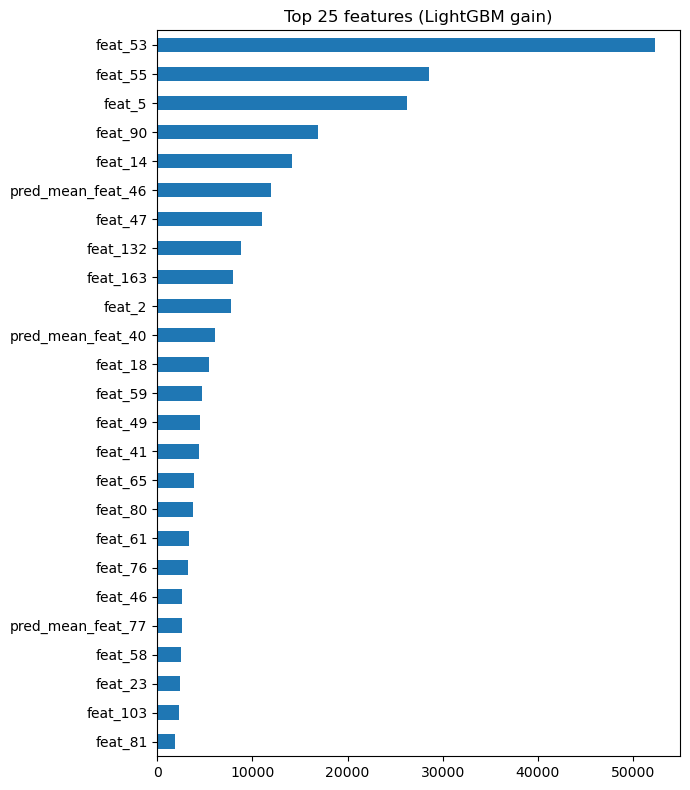

,experiment,mean_auc,fold_aucs
0,LightGBM | C: all + graph,0.998284,"[0.9987, 0.9984, 0.9978]"
1,LightGBM | D: all + graph + step ranks,0.998250,"[0.9984, 0.9983, 0.998]"
2,LightGBM | C: all + graph minus 20 drifting,0.998216,"[0.9986, 0.9983, 0.9977]"
3,Ensemble | lgb-heavy,0.998104,"[0.9987, 0.9979, 0.9977]"
4,Ensemble | lgb+rf,0.997919,"[0.9985, 0.9979, 0.9974]"
5,LightGBM | B: all original,0.997918,"[0.9982, 0.9982, 0.9973]"
6,Ensemble | lgb+rf+et,0.997804,"[0.9984, 0.9976, 0.9974]"
7,LightGBM | A: local only,0.997115,"[0.9975, 0.9971, 0.9968]"
8,RF | C: all + graph,0.996605,"[0.9972, 0.9965, 0.9961]"
9,ET | C: all + graph,0.994538,"[0.9962, 0.9947, 0.9927]"


In [10]:
# ===== 10. Feature importance =====
imp = pd.Series(np.mean([m.booster_.feature_importance('gain') for m in lgb_models], axis=0), index=BEST_COLS)
top = imp.sort_values(ascending=False).head(25)
ax = top[::-1].plot.barh(figsize=(7, 8))
ax.set_title('Top 25 features (LightGBM gain)')
plt.tight_layout()
plt.show()

# Summary of every experiment (time-based validation AUC)
rows = [{'experiment': 'LightGBM | ' + k, 'mean_auc': v['mean'], 'fold_aucs': np.round(v['aucs'], 4)} for k, v in results.items()]
rows += [{'experiment': mdl.upper() + ' | ' + best_name, 'mean_auc': model_cv[mdl]['mean'], 'fold_aucs': np.round(model_cv[mdl]['aucs'], 4)} for mdl in ['rf', 'et']]
rows += [{'experiment': 'Ensemble | ' + k, 'mean_auc': v['mean'], 'fold_aucs': np.round(v['aucs'], 4)} for k, v in ens_cv.items()]
summary = pd.DataFrame(rows).sort_values('mean_auc', ascending=False).reset_index(drop=True)
summary.to_csv(os.path.join(OUT_DIR, 'cv_results.csv'), index=False)
display(summary)